In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest

print("Environment ready!")

Environment ready!


In [2]:
from pathlib import Path
import sys

# Add project root to Python path
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data_quality.statsbomb import (
    load_statsbomb_events,
    flatten_statsbomb_events
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "statsbomb"
    / "real_madrid_liverpool_2018_events.json"
)

print("Dataset exists:", DATA_PATH.exists())
print("Dataset path:", DATA_PATH)

Dataset exists: True
Dataset path: /Users/onealokutu/Documents/ITU/5th semester /football-data-reality-check/data/raw/statsbomb/real_madrid_liverpool_2018_events.json


In [3]:
raw_events = load_statsbomb_events(DATA_PATH)

df = flatten_statsbomb_events(raw_events)

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (3497, 22)


,event_id,event_index,period,minute,second,event_type,team,player,x,y,...,pass_recipient,pass_length,pass_outcome,pass_complete,shot_xg,shot_outcome,is_goal,possession,possession_team,duration
0,5eee3ffd-f0c0-4532-868b-4a66cbf20cb8,1,1,0,0,Starting XI,Real Madrid,None,NaN,NaN,...,None,NaN,None,None,NaN,None,False,1,Real Madrid,0.000000
1,eaa65a92-02d3-4375-b2b7-7c2f679a620c,2,1,0,0,Starting XI,Liverpool,None,NaN,NaN,...,None,NaN,None,None,NaN,None,False,1,Real Madrid,0.000000
2,9c82d2e5-ebba-4825-b7f9-b11b04433ed8,3,1,0,0,Half Start,Real Madrid,None,NaN,NaN,...,None,NaN,None,None,NaN,None,False,1,Real Madrid,0.000000
3,b791047a-3eea-452f-b3a9-212bd40cd7cb,4,1,0,0,Half Start,Liverpool,None,NaN,NaN,...,None,NaN,None,None,NaN,None,False,1,Real Madrid,0.000000
4,25be91a5-a084-42cb-8cc1-a0fe7b0f52f9,5,1,0,0,Pass,Liverpool,James Philip Milner,60.0,40.0,...,Dejan Lovren,27.925795,None,True,NaN,None,False,2,Liverpool,1.735914


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3497 entries, 0 to 3496
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   event_id         3497 non-null   object 
 1   event_index      3497 non-null   int64  
 2   period           3497 non-null   int64  
 3   minute           3497 non-null   int64  
 4   second           3497 non-null   int64  
 5   event_type       3497 non-null   object 
 6   team             3497 non-null   object 
 7   player           3484 non-null   object 
 8   x                3470 non-null   float64
 9   y                3470 non-null   float64
 10  pass_end_x       1033 non-null   float64
 11  pass_end_y       1033 non-null   float64
 12  pass_recipient   978 non-null    object 
 13  pass_length      1033 non-null   float64
 14  pass_outcome     171 non-null    object 
 15  pass_complete    1033 non-null   object 
 16  shot_xg          28 non-null     float64
 17  shot_outcome  

In [5]:
missing = df.isna().sum().sort_values(ascending=False)

display(missing)

shot_outcome       3469
shot_xg            3469
pass_outcome       3326
pass_recipient     2519
pass_length        2464
pass_complete      2464
pass_end_x         2464
pass_end_y         2464
duration            978
x                    27
y                    27
player               13
event_index           0
event_id              0
event_type            0
second                0
minute                0
period                0
team                  0
is_goal               0
possession            0
possession_team       0
dtype: int64

In [6]:
# Select only pass events
pass_df = df[df["event_type"] == "Pass"].copy()

print("Number of pass events:", len(pass_df))

# Check missing values within pass events
pass_features = [
    "x",
    "y",
    "pass_end_x",
    "pass_end_y",
    "pass_length",
    "duration"
]

display(pass_df[pass_features].isna().sum())

# Inspect the numerical distributions
display(pass_df[pass_features].describe())


Number of pass events: 1033


x              0
y              0
pass_end_x     0
pass_end_y     0
pass_length    0
duration       0
dtype: int64

,x,y,pass_end_x,pass_end_y,pass_length,duration
count,1033.000000,1033.000000,1033.000000,1033.000000,1033.000000,1033.000000
mean,59.547919,39.495257,65.035915,39.439206,20.919550,1.493941
std,25.432903,25.517786,25.118081,25.297923,14.583986,0.859206
min,2.200000,0.100000,0.100000,0.100000,0.000000,0.054039
25%,42.700000,15.600000,48.400000,14.200000,10.447967,0.933854
50%,56.900000,39.700000,63.700000,39.300000,16.360012,1.268560
75%,77.300000,63.200000,84.400000,63.800000,27.181059,1.804835
max,120.000000,80.000000,120.000000,80.000000,93.741990,6.502557


In [7]:
# Calculate pass movement
pass_df["delta_x"] = pass_df["pass_end_x"] - pass_df["x"]
pass_df["delta_y"] = pass_df["pass_end_y"] - pass_df["y"]

# Calculate Euclidean distance from coordinates
pass_df["calculated_distance"] = np.sqrt(
    pass_df["delta_x"]**2 + pass_df["delta_y"]**2
)

# Compare recorded and calculated pass lengths
pass_df["distance_difference"] = (
    pass_df["pass_length"] - pass_df["calculated_distance"]
)

display(
    pass_df[
        [
            "x", "y",
            "pass_end_x", "pass_end_y",
            "pass_length",
            "calculated_distance",
            "distance_difference"
        ]
    ].head(10)
)

print(
    "Mean absolute distance difference:",
    pass_df["distance_difference"].abs().mean()
)

print(
    "Maximum absolute distance difference:",
    pass_df["distance_difference"].abs().max()
)

,x,y,pass_end_x,pass_end_y,pass_length,calculated_distance,distance_difference
4,60.0,40.0,32.1,41.2,27.925795,27.925795,4.723594e-07
7,35.0,40.8,92.7,22.7,60.472310,60.472308,2.288122e-06
11,27.4,60.2,36.1,71.6,14.340502,14.340502,-8.326054e-08
16,35.3,75.4,22.4,76.6,12.955694,12.955694,2.709865e-07
19,22.3,76.6,33.4,68.0,14.041723,14.041724,-5.409333e-07
23,36.2,75.3,43.6,62.0,15.220053,15.220053,4.376729e-07
25,76.5,18.1,84.8,9.5,11.951987,11.951987,-2.824564e-07
28,84.4,10.0,92.5,19.1,12.182775,12.182775,2.750041e-07
31,91.6,21.3,90.6,50.7,29.417002,29.417002,1.133359e-07
35,92.2,50.9,109.7,46.4,18.069311,18.069311,4.073470e-10


Mean absolute distance difference: 5.401330124875877e-07
Maximum absolute distance difference: 7.145229858451785e-06


In [8]:
# Select features for Isolation Forest
features = [
    "x",
    "y",
    "delta_x",
    "delta_y",
    "pass_length",
    "duration"
]

# Create the model input dataset
X = pass_df[features].copy()

# Check the dataset
print("Feature matrix shape:", X.shape)

print("\nMissing values:")
print(X.isna().sum())

print("\nFeature overview:")
display(X.describe())

Feature matrix shape: (1033, 6)

Missing values:
x              0
y              0
delta_x        0
delta_y        0
pass_length    0
duration       0
dtype: int64

Feature overview:


,x,y,delta_x,delta_y,pass_length,duration
count,1033.000000,1033.000000,1033.000000,1033.000000,1033.000000,1033.000000
mean,59.547919,39.495257,5.487996,-0.056050,20.919550,1.493941
std,25.432903,25.517786,17.137216,18.080644,14.583986,0.859206
min,2.200000,0.100000,-36.900000,-69.600000,0.000000,0.054039
25%,42.700000,15.600000,-5.700000,-10.500000,10.447967,0.933854
50%,56.900000,39.700000,3.100000,0.200000,16.360012,1.268560
75%,77.300000,63.200000,13.100000,9.700000,27.181059,1.804835
max,120.000000,80.000000,93.400000,70.100000,93.741990,6.502557


In [14]:
# Initialise Isolation Forest
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

# Train the model and predict anomalies
pass_df["anomaly_prediction"] = iso_forest.fit_predict(X)

# Count predictions
print(pass_df["anomaly_prediction"].value_counts())

anomaly_prediction
 1    981
-1     52
Name: count, dtype: int64


In [15]:
# Store predictions from each configuration
predictions_by_trees = {}

for trees in [50, 100, 200, 300, 500]:

    model = IsolationForest(
        n_estimators=trees,
        contamination=0.05,
        random_state=42
    )

    predictions_by_trees[trees] = model.fit_predict(X)

# Compare each model against the 500-tree model
reference = predictions_by_trees[500]

for trees, predictions in predictions_by_trees.items():

    agreement = (predictions == reference).mean()

    print(
        f"{trees} trees: "
        f"{agreement:.2%} agreement with 500-tree model"
    )

50 trees: 99.03% agreement with 500-tree model
100 trees: 98.64% agreement with 500-tree model
200 trees: 99.61% agreement with 500-tree model
300 trees: 99.61% agreement with 500-tree model
500 trees: 100.00% agreement with 500-tree model


In [16]:
# Extract potentially anomalous passes
anomalies = pass_df[
    pass_df["anomaly_prediction"] == -1
].copy()

print("Number of anomalies:", len(anomalies))

# Inspect their characteristics
display(
    anomalies[
        [
            "minute",
            "team",
            "player",
            "x",
            "y",
            "delta_x",
            "delta_y",
            "pass_length",
            "duration"
        ]
    ].head(15)
)

Number of anomalies: 52


,minute,team,player,x,y,delta_x,delta_y,pass_length,duration
79,1,Liverpool,Trent Alexander-Arnold,42.0,75.9,73.6,-16.6,75.448790,6.398595
343,6,Liverpool,James Philip Milner,86.3,23.1,3.6,52.2,52.323990,3.183400
399,8,Real Madrid,Keylor Navas Gamboa,7.0,36.1,62.8,19.0,65.611280,2.588255
471,10,Liverpool,Dejan Lovren,22.8,64.3,64.3,8.4,64.846360,3.447473
699,14,Liverpool,Trent Alexander-Arnold,49.1,74.5,7.5,-69.6,70.002930,3.043120
753,15,Liverpool,Loris Karius,20.9,45.0,48.7,-38.9,62.328964,3.586839
868,17,Real Madrid,Daniel Carvajal Ramos,28.8,73.0,-28.7,-44.7,53.120430,3.489887
870,17,Liverpool,Mohamed Salah,120.0,80.0,-4.4,-40.6,40.837727,1.804835
920,18,Real Madrid,Keylor Navas Gamboa,11.3,40.7,58.8,-39.9,71.059480,3.620569
987,21,Real Madrid,Sergio Ramos García,14.5,17.2,27.2,56.7,62.886642,3.257415


In [17]:
# Get anomaly scores from the trained model
# Higher values here mean more unusual
pass_df["anomaly_score"] = -iso_forest.score_samples(X)

# Sort from most unusual to least unusual
ranked_anomalies = pass_df[
    pass_df["anomaly_prediction"] == -1
].sort_values(
    by="anomaly_score",
    ascending=False
)

# Inspect the 10 most unusual passes
display(
    ranked_anomalies[
        [
            "minute",
            "team",
            "player",
            "x",
            "y",
            "delta_x",
            "delta_y",
            "pass_length",
            "duration",
            "anomaly_score"
        ]
    ].head(10)
)

,minute,team,player,x,y,delta_x,delta_y,pass_length,duration,anomaly_score
1084,23,Real Madrid,Keylor Navas Gamboa,14.9,36.4,93.4,8.0,93.741990,5.595453,0.688841
79,1,Liverpool,Trent Alexander-Arnold,42.0,75.9,73.6,-16.6,75.448790,6.398595,0.685238
1617,40,Liverpool,Jordan Brian Henderson,36.7,40.9,77.8,35.2,85.392500,5.851886,0.684609
2053,48,Real Madrid,Sergio Ramos García,13.8,13.0,14.5,62.4,64.062546,4.781050,0.664254
2836,72,Real Madrid,Keylor Navas Gamboa,8.9,39.7,69.7,-15.0,71.295790,5.319610,0.663269
3421,90,Real Madrid,José Ignacio Fernández Iglesias,40.0,72.9,2.6,-69.2,69.248825,4.176573,0.653234
3262,85,Liverpool,Loris Karius,7.0,36.1,78.1,-23.8,81.645880,3.692919,0.646215
3261,85,Real Madrid,Carlos Henrique Casimiro,54.8,43.6,64.8,26.6,70.047130,4.669800,0.643398
2169,54,Liverpool,James Philip Milner,120.0,80.0,-10.2,-44.6,45.751503,2.789706,0.635514
1197,30,Real Madrid,Keylor Navas Gamboa,6.8,41.2,21.3,-36.6,42.346783,6.502557,0.634837


In [18]:
# Check whether flagged passes have invalid starting coordinates
invalid_start = (
    (anomalies["x"] < 0) |
    (anomalies["x"] > 120) |
    (anomalies["y"] < 0) |
    (anomalies["y"] > 80)
)

# Check ending coordinates
invalid_end = (
    (anomalies["pass_end_x"] < 0) |
    (anomalies["pass_end_x"] > 120) |
    (anomalies["pass_end_y"] < 0) |
    (anomalies["pass_end_y"] > 80)
)

print("Flagged passes:", len(anomalies))
print("Invalid starting coordinates:", invalid_start.sum())
print("Invalid ending coordinates:", invalid_end.sum())
print("Passes with invalid coordinates:",
      (invalid_start | invalid_end).sum())

Flagged passes: 52
Invalid starting coordinates: 0
Invalid ending coordinates: 0
Passes with invalid coordinates: 0


In [19]:
# Rule 1: Check pitch boundaries
pass_df["coordinate_violation"] = (
    (pass_df["x"] < 0) | (pass_df["x"] > 120) |
    (pass_df["y"] < 0) | (pass_df["y"] > 80) |
    (pass_df["pass_end_x"] < 0) |
    (pass_df["pass_end_x"] > 120) |
    (pass_df["pass_end_y"] < 0) |
    (pass_df["pass_end_y"] > 80)
)

# Rule 2: Check pass-length consistency
pass_df["length_violation"] = (
    pass_df["distance_difference"].abs() > 0.001
)

# Combine rule-based checks
pass_df["rule_violation"] = (
    pass_df["coordinate_violation"] |
    pass_df["length_violation"]
)

# Compare ML and rule-based results
comparison = pd.crosstab(
    pass_df["anomaly_prediction"] == -1,
    pass_df["rule_violation"],
    rownames=["Isolation Forest anomaly"],
    colnames=["Rule-based violation"]
)

display(comparison)

print("\nTotal rule violations:",
      pass_df["rule_violation"].sum())

print("Total ML anomalies:",
      (pass_df["anomaly_prediction"] == -1).sum())
      

Rule-based violation,False
Isolation Forest anomaly,
False,981
True,52



Total rule violations: 0
Total ML anomalies: 52


In [20]:
# Select one ordinary pass as our starting point
normal_pass = pass_df[
    pass_df["anomaly_prediction"] == 1
].iloc[0].copy()

# Create a separate copy
synthetic_anomalies = pd.DataFrame(
    [normal_pass.copy() for _ in range(3)]
)

synthetic_anomalies.index = [
    "Impossible coordinate",
    "Unusual duration",
    "Extreme pass distance"
]

synthetic_anomalies

,event_id,event_index,period,minute,second,event_type,team,player,x,y,...,duration,delta_x,delta_y,calculated_distance,distance_difference,anomaly_prediction,anomaly_score,coordinate_violation,length_violation,rule_violation
Impossible coordinate,25be91a5-a084-42cb-8cc1-a0fe7b0f52f9,5,1,0,0,Pass,Liverpool,James Philip Milner,60.0,40.0,...,1.735914,-27.9,1.2,27.925795,4.723594e-07,1,0.47327,False,False,False
Unusual duration,25be91a5-a084-42cb-8cc1-a0fe7b0f52f9,5,1,0,0,Pass,Liverpool,James Philip Milner,60.0,40.0,...,1.735914,-27.9,1.2,27.925795,4.723594e-07,1,0.47327,False,False,False
Extreme pass distance,25be91a5-a084-42cb-8cc1-a0fe7b0f52f9,5,1,0,0,Pass,Liverpool,James Philip Milner,60.0,40.0,...,1.735914,-27.9,1.2,27.925795,4.723594e-07,1,0.47327,False,False,False


In [21]:
synthetic_anomalies.loc["Impossible coordinate", "x"] = 150

synthetic_anomalies.loc["Unusual duration", "duration"] = 60

synthetic_anomalies.loc["Extreme pass distance", "pass_length"] = 200

synthetic_anomalies[
    ["x", "duration", "pass_length"]
]

,x,duration,pass_length
Impossible coordinate,150.0,1.735914,27.925795
Unusual duration,60.0,60.000000,27.925795
Extreme pass distance,60.0,1.735914,200.000000


Synthetic for Isolation Forest

In [23]:
synthetic_X = synthetic_anomalies[features].copy()
synthetic_predictions = iso_forest.predict(synthetic_X)

synthetic_results = pd.DataFrame({
    "injected_anomaly": synthetic_anomalies.index,
    "prediction": synthetic_predictions,
    "anomaly_score": -iso_forest.score_samples(synthetic_X)
})

synthetic_results

,injected_anomaly,prediction,anomaly_score
0,Impossible coordinate,1,0.557234
1,Unusual duration,-1,0.585386
2,Extreme pass distance,-1,0.592425


In [30]:
synthetic_anomalies["coordinate_violation"] = (
    (synthetic_anomalies["x"] < 0) |
    (synthetic_anomalies["x"] > 120) |
    (synthetic_anomalies["y"] < 0) |
    (synthetic_anomalies["y"] > 80) |
    (synthetic_anomalies["pass_end_x"] < 0) |
    (synthetic_anomalies["pass_end_x"] > 120) |
    (synthetic_anomalies["pass_end_y"] < 0) |
    (synthetic_anomalies["pass_end_y"] > 80)
)
synthetic_anomalies["calculated_distance"] = np.sqrt(
    (synthetic_anomalies["pass_end_x"] - synthetic_anomalies["x"])**2
    + (synthetic_anomalies["pass_end_y"] - synthetic_anomalies["y"])**2
)

synthetic_anomalies["distance_difference"] = (
    synthetic_anomalies["pass_length"]
    - synthetic_anomalies["calculated_distance"]
)

synthetic_anomalies["length_violation"] = (
    synthetic_anomalies["distance_difference"].abs() > 0.001
)

synthetic_anomalies["rule_violation"] = (
    synthetic_anomalies["coordinate_violation"]
    | synthetic_anomalies["length_violation"]
)

synthetic_anomalies[
    ["coordinate_violation", "length_violation", "rule_violation"]
]

,coordinate_violation,length_violation,rule_violation
Impossible coordinate,True,True,True
Unusual duration,False,False,False
Extreme pass distance,False,True,True


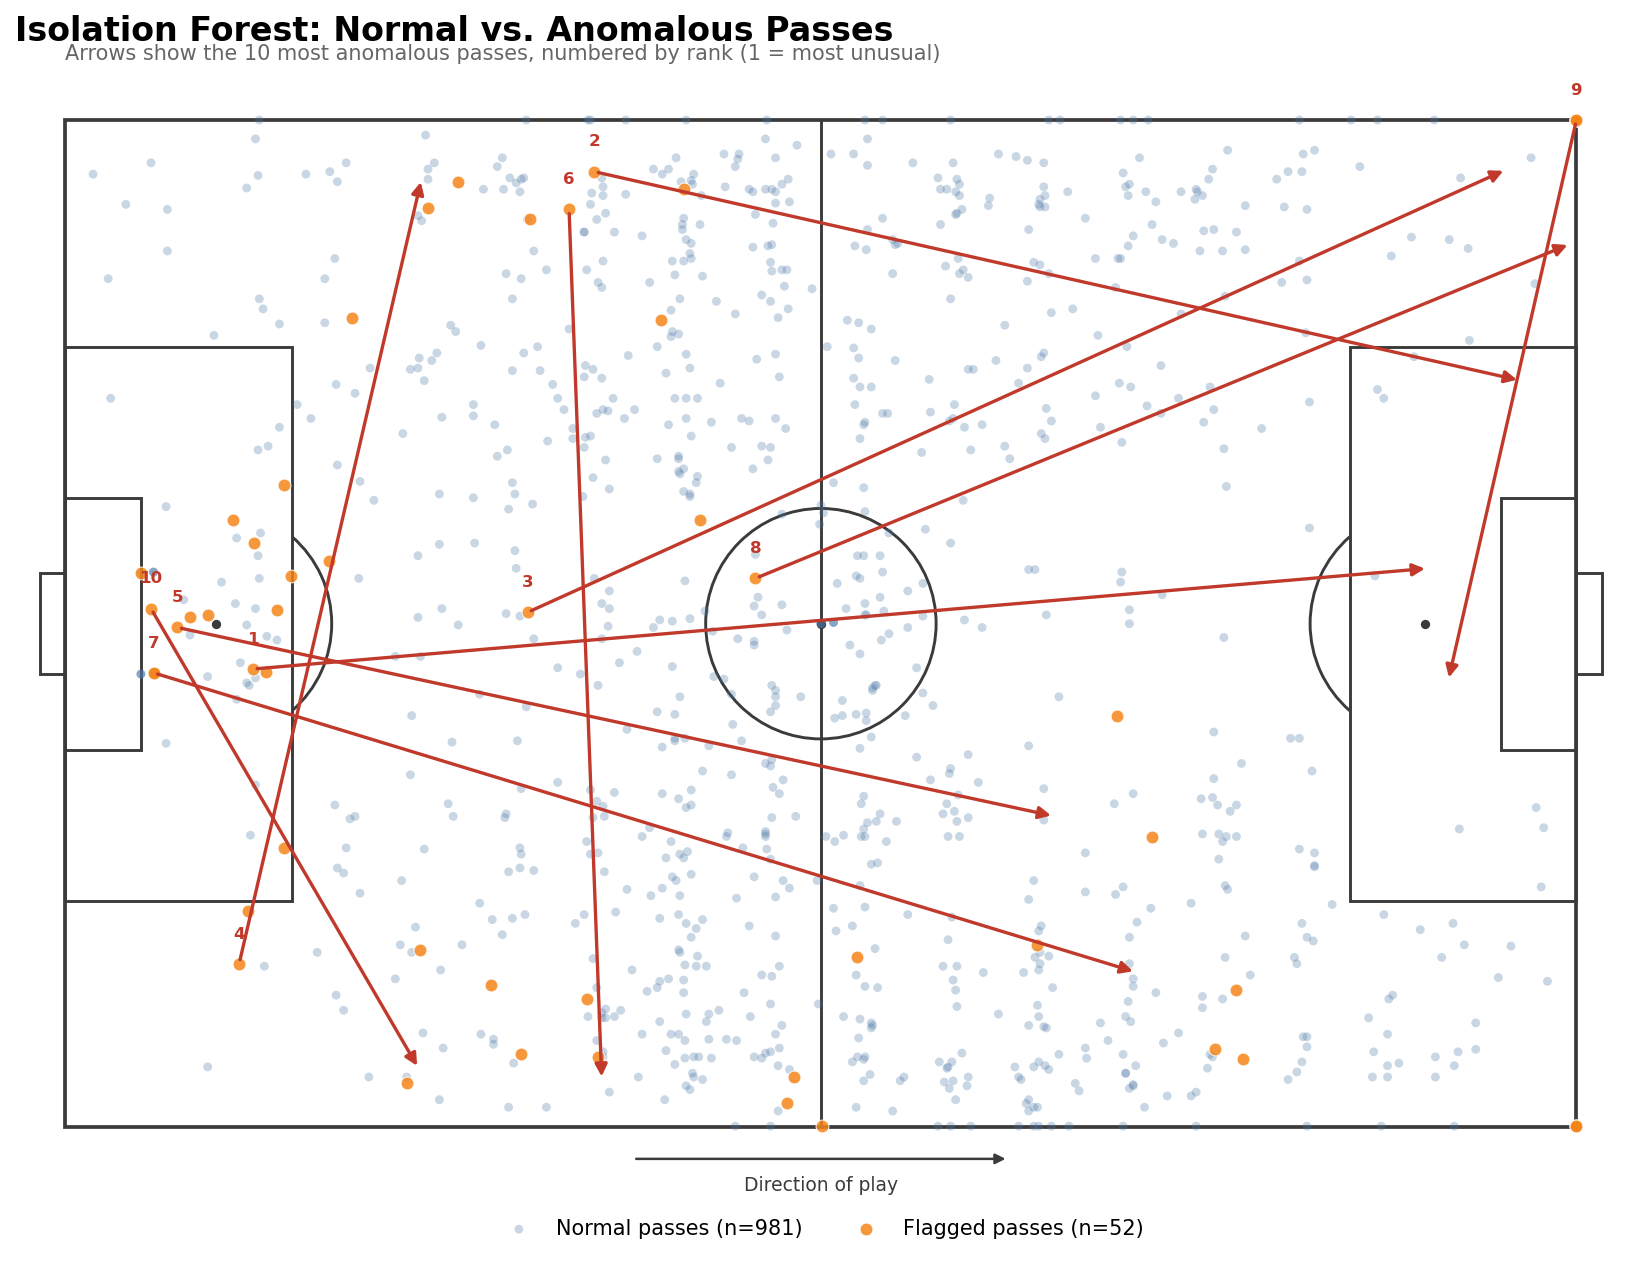

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Arc


def draw_pitch(ax, pitch_color="#f7f7f2", line_color="#3b3b3b", lw=1.4):
    """Draw a 120x80 football pitch with standard markings."""
    ax.set_facecolor(pitch_color)

    # Outline and halfway line
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=line_color, lw=lw + 0.4))
    ax.plot([60, 60], [0, 80], color=line_color, lw=lw)

    # Centre circle and spot
    ax.add_patch(Circle((60, 40), 9.15, fill=False, ec=line_color, lw=lw))
    ax.scatter(60, 40, color=line_color, s=12, zorder=2)

    # Penalty areas and six-yard boxes
    for x0, w in [(0, 18), (102, 18)]:
        ax.add_patch(Rectangle((x0, 18), w, 44, fill=False, ec=line_color, lw=lw))
    for x0, w in [(0, 6), (114, 6)]:
        ax.add_patch(Rectangle((x0, 30), w, 20, fill=False, ec=line_color, lw=lw))

    # Penalty spots and arcs
    ax.scatter([12, 108], [40, 40], color=line_color, s=12, zorder=2)
    ax.add_patch(Arc((12, 40), 18.3, 18.3, theta1=-49, theta2=49, ec=line_color, lw=lw))
    ax.add_patch(Arc((108, 40), 18.3, 18.3, theta1=131, theta2=229, ec=line_color, lw=lw))

    # Goals
    ax.add_patch(Rectangle((-2, 36), 2, 8, fill=False, ec=line_color, lw=lw))
    ax.add_patch(Rectangle((120, 36), 2, 8, fill=False, ec=line_color, lw=lw))

    ax.set_xlim(-4, 124)
    ax.set_ylim(-4, 84)
    ax.set_aspect("equal")
    ax.axis("off")


# --- Data ---
normal_passes = pass_df[pass_df["anomaly_prediction"] == 1]
anomalous_passes = pass_df[pass_df["anomaly_prediction"] == -1]
top_10 = anomalous_passes.nlargest(10, "anomaly_score")

# --- Plot ---
fig, ax = plt.subplots(figsize=(13, 8.5), dpi=150)
draw_pitch(ax)

ax.scatter(
    normal_passes["x"], normal_passes["y"],
    s=18, color="#4c78a8", alpha=0.30, edgecolors="none",
    label=f"Normal passes (n={len(normal_passes):,})", zorder=3,
)
ax.scatter(
    anomalous_passes["x"], anomalous_passes["y"],
    s=38, color="#f58518", alpha=0.85, edgecolors="white", linewidths=0.5,
    label=f"Flagged passes (n={len(anomalous_passes):,})", zorder=4,
)

# Top 10 most unusual passes, numbered by rank
for rank, (_, row) in enumerate(top_10.iterrows(), start=1):
    ax.annotate(
        "", xy=(row["pass_end_x"], row["pass_end_y"]), xytext=(row["x"], row["y"]),
        arrowprops=dict(arrowstyle="-|>", color="#c0392b", lw=1.6, mutation_scale=12),
        zorder=5,
    )
    ax.text(
        row["x"], row["y"] + 1.8, str(rank),
        fontsize=8, fontweight="bold", color="#c0392b",
        ha="center", va="bottom", zorder=6,
    )

# Attack direction
ax.annotate(
    "", xy=(75, -2.5), xytext=(45, -2.5),
    arrowprops=dict(arrowstyle="-|>", color="#3b3b3b", lw=1.2),
)
ax.text(60, -3.8, "Direction of play", ha="center", va="top", fontsize=9, color="#3b3b3b")

# Titles and legend
ax.set_title(
    "Isolation Forest: Normal vs. Anomalous Passes",
    fontsize=16, fontweight="bold", loc="left", pad=14,
)
ax.text(
    0, 84.5, "Arrows show the 10 most anomalous passes, numbered by rank (1 = most unusual)",
    fontsize=10, color="#666666", ha="left", va="bottom",
)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2,
    frameon=False, fontsize=10,
)

fig.tight_layout()
plt.show()
# fig.savefig("anomalous_passes.png", dpi=300, bbox_inches="tight")

In [28]:
comparison_summary = pd.DataFrame({
    "Normal passes": normal_passes[
        ["pass_length", "duration"]
    ].mean(),
    "Flagged passes": anomalous_passes[
        ["pass_length", "duration"]
    ].mean()
})

comparison_summary

,Normal passes,Flagged passes
pass_length,18.891191,59.185327
duration,1.383222,3.582694


# Conclusion and Findings

## Research Question

Can unsupervised machine learning complement traditional rule-based validation by identifying unusual football events that predefined data-quality checks might overlook?

## Methodology

The project used StatsBomb event data from the 2018 UEFA Champions League final between Real Madrid and Liverpool.

The analysis focused on 1,033 pass events. Six numerical features were selected:

- Starting coordinates (`x`, `y`)
- Pass direction (`delta_x`, `delta_y`)
- Pass length (`pass_length`)
- Pass duration (`duration`)

An Isolation Forest model was trained using 200 trees and a contamination parameter of 0.05.

The model identified 52 potentially anomalous passes, representing approximately 5% of the dataset.

These observations were then investigated using anomaly scores, visualisations and existing rule-based validation checks.

A controlled experiment was also conducted by introducing three artificial anomalies into copies of an ordinary pass.

## Key Findings

1. Isolation Forest identified 52 potentially unusual passes out of 1,033.
2. Flagged passes had an average length of 59.19 metres, compared with 18.89 metres for normal passes.
3. Flagged passes had an average duration of 3.58 seconds, compared with 1.38 seconds for normal passes.
4. None of the 52 flagged passes violated the two original checks for pitch boundaries and pass-length consistency.
5. The controlled experiment demonstrated that rule-based validation and Isolation Forest can detect different types of abnormalities.

## Limitations

- The analysis focused on a single football match, limiting generalisation.
- The model was trained without labelled examples of incorrect data.
- The contamination parameter was configured at 5%, influencing the number of observations flagged.
- The model identifies statistical unusualness, not confirmed data errors.
- The artificial anomaly experiment used only three deliberately extreme examples.
- The selected features do not capture every aspect of football context or tactical behaviour.

## Conclusion

The project demonstrates how unsupervised machine learning can complement traditional rule-based data validation.

Rule-based checks are effective for identifying predefined violations, such as impossible pitch coordinates and inconsistent pass lengths. Isolation Forest offers another perspective by identifying statistically unusual combinations of football event characteristics.

However, an anomalous observation should not automatically be classified as incorrect data. It should instead be treated as a candidate for further investigation.

Combining both approaches provides a more comprehensive framework for exploring football event data quality.
